# COMO tutorial — recognizing drug molecules from images

This notebook walks through the full inference workflow of
[COMO](https://github.com/netknowledge/COMO) on the ten bundled sample
images (common drug molecules):

1. load a checkpoint (downloaded automatically from HuggingFace),
2. predict a single image → SMILES with confidence,
3. batch-predict all samples and tabulate them against ground truth,
4. render any mismatch with RDKit and check tautomer-normalized matching.

Required packages: `como-ocsr`, `huggingface_hub`

```bash
pip install como-ocsr huggingface_hub
```

In [1]:
import os

# work with a pip install or from a repository clone
try:
    import como
except ImportError:
    import pathlib
    _parent = pathlib.Path(os.getcwd()).resolve().parent
    import sys
    sys.path.insert(0, str(_parent))
    import como

print(f'como {como.__version__ if hasattr(como, "__version__") else "(dev repo)"} importable on {os.uname().nodename}')

como 1.3.1 importable on DS209210


## 1. Configurate & fetch a checkpoint

The released checkpoints live on HuggingFace
([Keylab/COMO](https://huggingface.co/Keylab/COMO)). Set `COMO_CHECKPOINT`
in the environment to reuse an existing local file instead of
downloading.

In [2]:
CHECKPOINT = os.environ.get("COMO_CHECKPOINT")
if not CHECKPOINT:
    from huggingface_hub import hf_hub_download

    CHECKPOINT = hf_hub_download(
        repo_id="Keylab/COMO",
        filename="models/edit_distance/final.pth",  # released joint MLE+MRT recipe
        local_dir=os.path.join(os.getcwd(), "artifacts"),
    )
print(CHECKPOINT)

/home/junjdong/zqlyu/projects/COMO/COMO_dev/examples/artifacts/models/edit_distance/final.pth


## 2. Load the model

`device` falls back to CPU automatically when no GPU is present.

In [3]:
import torch

device = "cuda:0" if torch.cuda.is_available() else "cpu"
print(f"device: {device}")
model = como.load_model(CHECKPOINT, device=device)
print("model loaded")

device: cpu


Model loaded from: /home/junjdong/zqlyu/projects/COMO/COMO_dev/examples/artifacts/models/edit_distance/final.pth
model loaded


## 3. Predict a single image

image:      Metformin.png
SMILES:     CN(C)C(=N)N=C(N)N
confidence: 0.917


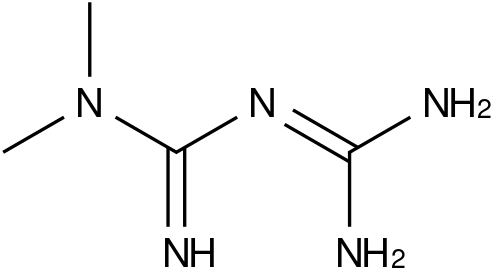

In [4]:
from PIL import Image

IMAGE = os.path.join(os.getcwd(), "sample_images", "Metformin.png")

smiles, conf = como.predict(model, IMAGE, return_confidence=True)
print(f"image:      {os.path.basename(IMAGE)}")
print(f"SMILES:     {smiles}")
print(f"confidence: {conf:.3f}")
Image.open(IMAGE)

## 4. Batch prediction on all samples

Ground truth is in `examples.csv` (`name, SMILES`). We compare
canonical SMILES strings (RDKit) and report a per-molecule
confidence signal as well.

In [5]:
import pandas as pd

df = pd.read_csv(os.path.join(os.getcwd(), "examples.csv"))

paths = [os.path.join(os.getcwd(), "sample_images", f"{n}.png") for n in df["name"]]
preds = como.predict_batch(model, paths, internal_batch_size=8, return_confidence=True)

df["prediction"] = [p[0] for p in preds]
df["confidence"] = [round(p[1], 3) for p in preds]
df["exact"] = [
    (como.canonicalize_smiles(ref)[0] == como.canonicalize_smiles(prd)[0])
    if prd else False
    for ref, prd in zip(df["SMILES"], df["prediction"])
]
df[["name", "exact", "confidence", "SMILES", "prediction"]]

,name,exact,confidence,SMILES,prediction
0,Amlodipine,True,0.919,CCOC(=O)C1=C(NC(=C(C1C2=CC=CC=C2Cl)C(=O)OC)C)C...,CCOC(=O)C1=C(COCCN)NC(C)=C(C(=O)OC)C1c1ccccc1Cl
1,Atorvastatin,True,0.917,CC(C)C1=C(C(=C(N1CC[C@H](C[C@H](CC(=O)O)O)O)C2...,CC(C)c1c(C(=O)Nc2ccccc2)c(-c2ccccc2)c(-c2ccc(F...
2,Gabapentin,True,0.918,C1CCC(CC1)(CC(=O)O)CN,NCC1(CC(=O)O)CCCCC1
3,Levothyroxine,True,0.917,C1=C(C=C(C(=C1I)OC2=CC(=C(C(=C2)I)O)I)I)C[C@@H...,N[C@@H](Cc1cc(I)c(Oc2cc(I)c(O)c(I)c2)c(I)c1)C(...
4,Lisinopril,True,0.917,C1C[C@H](N(C1)C(=O)[C@H](CCCCN)N[C@@H](CCC2=CC...,NCCCC[C@H](N[C@@H](CCc1ccccc1)C(=O)O)C(=O)N1CC...
5,Losartan,True,0.917,CCCCC1=NC(=C(N1CC2=CC=C(C=C2)C3=CC=CC=C3C4=NNN...,CCCCc1nc(Cl)c(CO)n1Cc1ccc(-c2ccccc2-c2nn[nH]n2...
6,Metformin,True,0.917,CN(C)C(=N)N=C(N)N,CN(C)C(=N)N=C(N)N
7,Metoprolol,True,0.917,CC(C)NCC(COC1=CC=C(C=C1)CCOC)O,COCCc1ccc(OCC(O)CNC(C)C)cc1
8,Salbutamol,True,0.917,CC(C)(C)NCC(C1=CC(=C(C=C1)O)CO)O,CC(C)(C)NCC(O)c1ccc(O)c(CO)c1
9,Sertraline,True,0.918,CN[C@H]1CC[C@H](C2=CC=CC=C12)C3=CC(=C(C=C3)Cl)Cl,CN[C@H]1CC[C@@H](c2ccc(Cl)c(Cl)c2)c2ccccc21


## 5. Failures & tautomer check

Tautomer normalization maps different tautomeric forms (keto/enol,
lactam/lactim, ...) to a shared canonical form — a match after this
normalization is chemically equivalent, not literally identical.

In [6]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.MolStandardize import rdMolStandardize
from IPython.display import display

enumerator = rdMolStandardize.TautomerEnumerator()


def tautomer_canonicalize(s):
    if not s:
        return None
    m = enumerator.Canonicalize(Chem.MolFromSmiles(s)) if Chem.MolFromSmiles(s) else None
    return Chem.MolToSmiles(m) if m else None


df["tautomer"] = [
    (tautomer_canonicalize(ref) == tautomer_canonicalize(prd)) if prd else False
    for ref, prd in zip(df["SMILES"], df["prediction"])
]

print(f"exact:              {df['exact'].sum()}/{len(df)}")
print(f"tautomer-normalized: {df['tautomer'].sum()}/{len(df)}")

failed = df[~df["tautomer"]]
if failed.empty:
    print("all samples recognized.")
else:
    mols = [Chem.MolFromSmiles(s) for s in failed["SMILES"]]
    preds = [Chem.MolFromSmiles(p) for p in failed["prediction"]]
    pairs = [m if m is not None else Chem.MolFromSmiles("C") for m in mols + preds]
    display(Draw.MolsToGridImage(pairs, molsPerRow=2,
                                 legends=[f"{n}: ref" for n in failed["name"]]
                                 + [f"{n}: pred" for n in failed["name"]]))

exact:              10/10
tautomer-normalized: 10/10
all samples recognized.


## Next steps

- [doc/getting_started.md](../doc/getting_started.md) — installation,
checkpoint table, benchmark evaluation
- [doc/api_reference.md](../doc/api_reference.md) — full API reference
(`predict_batch` options, confidence signals, multi-GPU benchmark runs)
- [doc/training.md](../doc/training.md) — training & fine-tuning recipes
- [predict_batch.py](predict_batch.py) / [predict_single.py](predict_single.py)
— the CLI versions of this workflow